# Beta-Anclado-OU: menos rotación, umbrales que pagan el costo

**Problema (de la auditoría):** el borde bruto real es ~0.17% por ventana de 30 días y los costos se lo comen. El Kalman dinámico hace ~28 operaciones por ventana y pierde; el β estático hace ~9 y queda en cero.

**Idea 1 – β anclado:** calibrar β una sola vez con una ventana larga y *congelarlo* en toda la ventana de prueba. Sin recalibrar no hay rebalanceo ni costo extra, y el P&L es exactamente $\Delta y-\beta^\top\Delta X$.

**Idea 2 – umbrales con costo:** en vez de entrar en $z=2$ por costumbre, ajustamos un proceso de Ornstein-Uhlenbeck (OU) al spread de entrenamiento, simulamos la ganancia esperada neta de cada par (entrada $k$, salida $e$) y elegimos el mejor. **Si ninguno gana tras costos, la ventana se abstiene** (no opera).

**Reglas de honestidad:** (1) contabilidad corregida (pesos congelados, costo en todas las patas); (2) placebo con caminatas aleatorias; (3) se reportan bruto, neto y break-even juntos; (4) las mismas ventanas de prueba para todas las configuraciones.

In [3]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from scipy.signal import lfilter
import warnings; warnings.filterwarnings('ignore')
try:
    from numba import njit          # opcional: !pip install numba (acelera ~50x)
except ImportError:
    njit = lambda f: f

## Fase 1 – Datos (renombrando por ticker, con verificación de niveles)

In [4]:
import yfinance as yf
tickers = {'USDCAD':'USDCAD=X','USDNOK':'USDNOK=X','USDSEK':'USDSEK=X','USDSGD':'USDSGD=X'}
raw = yf.download(list(tickers.values()), period='729d', interval='60m', progress=False, auto_adjust=True)['Close']
ticker_to_name = {v: k for k, v in tickers.items()}
data = raw.rename(columns=ticker_to_name)[list(tickers.keys())].ffill().dropna()
if data.index.tz is not None:
    data.index = data.index.tz_convert('UTC').tz_localize(None)

In [5]:
expected = {'USDCAD':(1.0,2.0),'USDNOK':(7,15),'USDSEK':(7,15),'USDSGD':(1.0,2.0)}
summary = pd.DataFrame({'media':data.mean(),'min':data.min(),'max':data.max()})
summary['ok'] = [expected[c][0] <= summary.loc[c,'media'] <= expected[c][1] for c in summary.index]
display(summary); print(data.shape, data.index.min(), '->', data.index.max())
assert summary['ok'].all(), 'Algún nivel de precio no corresponde a su nombre'

,media,min,max,ok
Ticker,,,,
USDCAD,1.384998,1.33195,1.47812,True
USDNOK,10.279869,9.14918,11.51141,True
USDSEK,9.973642,8.76675,11.29890,True
USDSGD,1.309330,1.25968,1.37474,True


(17326, 4) 2024-01-04 00:00:00 -> 2026-10-20 22:00:00


## Fase 2 – Parámetros y motor

In [6]:
Y  = 'USDCAD'                       # pata dependiente
XS = ['USDNOK','USDSEK','USDSGD']   # patas explicativas
COST_BPS  = 1.0                     # por pata, por lado
TEST_DAYS = 30
MIN_TRAIN = 240                     # primer día de prueba; así todas las configs comparten ventanas
STOP      = 3.5                     # stop-loss en unidades de sigma
FIXED_KE  = (2.0, 0.5)              # umbrales "de costumbre"

**Piezas del motor** (intuición): `calibrate` ajusta β por OLS en entrenamiento y define el spread $s=y-\beta^\top X-\alpha$. `fit_ou` mide qué tan rápido regresa el spread a su media ($b$ = autocorrelación a 1 hora; vida media $=\ln 2/(-\ln b)$). `positions_from_z` es la máquina de estados (entrar en $|z|\ge k$, salir en $|z|\le e$, stop en $3.5$, bloqueo tras stop hasta volver a $|z|<k$). `ou_band_search` simula miles de horas de un OU con el $b$ ajustado y evalúa cada $(k,e)$ *restando el costo*.

In [7]:
def calibrate(train):
    A = np.column_stack([np.ones(len(train))] + [train[c].values for c in XS])
    coef, *_ = np.linalg.lstsq(A, train[Y].values, rcond=None)
    alpha, beta = coef[0], coef[1:]
    s = train[Y].values - train[XS].values @ beta - alpha
    return alpha, beta, s

def fit_ou(s):
    x, y = s[:-1], s[1:]
    b, a = np.polyfit(x, y, 1)
    if not (0.0 < b < 1.0):
        return None
    resid = y - (a + b*x)
    return dict(b=b, mu=a/(1-b), sig=resid.std(ddof=2)/np.sqrt(1-b*b), hl=np.log(2)/(-np.log(b)))

@njit
def positions_from_z(z, k, e, stop):
    n = len(z); pos = np.zeros(n); p = 0.0; blocked = 0.0
    for t in range(n):
        zt = z[t]
        if blocked != 0.0 and abs(zt) < k:
            blocked = 0.0
        if p == 0.0:
            if blocked == 0.0:
                if zt >= k: p = -1.0
                elif zt <= -k: p = 1.0
        else:
            if p < 0 and zt <= e: p = 0.0
            elif p > 0 and zt >= -e: p = 0.0
            elif abs(zt) >= stop:
                blocked = 1.0 if zt > 0 else -1.0
                p = 0.0
        pos[t] = p
    return pos

def ou_band_search(b, c_side_z, n=60000, seed=0, ks=np.arange(0.75, 3.01, 0.25), es=(0.0, 0.25, 0.5, 1.0)):
    # OU estandarizado (varianza 1) con autocorrelación b; costo por lado en unidades de z
    eps = np.random.default_rng(seed).standard_normal(n) * np.sqrt(1 - b*b)
    z = lfilter([1.0], [1.0, -b], eps)
    dz = np.diff(z); best = None
    for k in ks:
        for e in es:
            if e >= k: continue
            pos = positions_from_z(z, k, e, STOP)
            gross = (pos[:-1] * dz).sum()
            cost = c_side_z * np.abs(np.diff(pos, prepend=0.0)).sum()
            rate = (gross - cost) / n
            if best is None or rate > best[2]:
                best = (k, e, rate)
    return best if best and best[2] > 0 else None   # None = abstenerse

## Fase 3 – Walk-forward (mismas ventanas de prueba para todas las configuraciones)

Cada ventana de prueba dura 30 días. Se compara: **fijo 2.0/0.5** vs **OU con costo**, con β anclado en **120** o **240** días previos. Retornos normalizados por la exposición bruta media del entrenamiento (nocional = $y+\sum|\beta_i|X_i$). `ops` = entradas a posición.

In [8]:
def run_cfg(df, train_days, mode, cost_bps=COST_BPS, seed=0):
    day = df.index.normalize().values
    ud = np.unique(day); rows = []
    for j in range(MIN_TRAIN, len(ud) - TEST_DAYS + 1, TEST_DAYS):
        tr = df[(day >= ud[j-train_days]) & (day < ud[j])]
        te = df[(day >= ud[j]) & (day < ud[j+TEST_DAYS])]
        row = dict(window=j, gross=0.0, net=0.0, cost=0.0, ops=0, k=np.nan, e=np.nan, hl=np.nan)
        alpha, beta, s = calibrate(tr)
        ou = fit_ou(s)
        if ou is None or len(te) < 50:
            rows.append(row); continue
        E = (tr[Y].values + tr[XS].values @ np.abs(beta)).mean()
        c_side_z = (cost_bps/1e4) * E / ou['sig']
        row['hl'] = ou['hl']
        if mode == 'fixed':
            k, e = FIXED_KE
        else:
            res = ou_band_search(ou['b'], c_side_z, seed=seed)
            if res is None:
                rows.append(row); continue
            k, e = res[0], res[1]
        s_te = te[Y].values - te[XS].values @ beta - alpha      # pesos congelados
        z = (s_te - ou['mu']) / ou['sig']
        pos = positions_from_z(z, k, e, STOP)
        gross = (pos[:-1] * np.diff(s_te)).sum()
        notional = te[Y].values + te[XS].values @ np.abs(beta)
        cost = (np.abs(np.diff(pos, prepend=0.0)) * notional).sum() * cost_bps/1e4
        row.update(gross=gross/E, cost=cost/E, net=(gross-cost)/E,
                   ops=int(((pos[1:] != 0) & (pos[:-1] == 0)).sum() + (pos[0] != 0)), k=k, e=e)
        rows.append(row)
    return pd.DataFrame(rows)

def summarize(res, label):
    g, n = res.gross, res.net
    be = g.mean() / res.cost.mean() * COST_BPS if res.cost.mean() > 0 else np.nan
    return pd.Series({
        'bruto': g.mean(), 'p_bruto': stats.ttest_1samp(g, 0).pvalue,
        'neto': n.mean(), 'p_neto': stats.ttest_1samp(n, 0).pvalue,
        'neto>0': f"{(n>0).sum()}/{len(n)}", 'abstenidas': int((res.ops==0).sum()),
        'ops/vent': res.ops.mean(), 'break-even bps': be}, name=label)

In [9]:
cfgs = {'fijo_120':(120,'fixed'), 'ou_120':(120,'ou'), 'fijo_240':(240,'fixed'), 'ou_240':(240,'ou')}
results = {name: run_cfg(data, td, mode) for name,(td,mode) in cfgs.items()}
table = pd.DataFrame([summarize(r, n) for n, r in results.items()])
display(table.round(5))

,bruto,p_bruto,neto,p_neto,neto>0,abstenidas,ops/vent,break-even bps
fijo_120,0.00099,0.25334,0.00067,0.43289,11/19,2,1.63158,3.12303
ou_120,0.00060,0.69161,0.00012,0.93534,13/19,0,2.52632,1.25036
fijo_240,0.00032,0.76913,0.00013,0.90633,8/19,6,1.00000,1.67005
ou_240,-0.00071,0.62848,-0.00100,0.48764,9/19,0,1.78947,-2.41149


**Cómo leer la tabla:** `neto` es lo único que paga. `break-even bps` es el costo por pata al que el neto sería cero (si es mayor que 1, hay colchón). `abstenidas` son ventanas donde el modelo decidió que no valía la pena operar. Si `p_neto` no es chica y el neto no es positivo, **no hay estrategia**, aunque el bruto sea significativo.

## Fase 4 – Diagnóstico: ¿qué ganamos por operación vs. qué cuesta?

,cfg,vida_media_h,k_med,e_med,bruto_por_op,costo_por_op
0,fijo_120,80.71879,2.00,0.5,0.00072,0.00019
1,ou_120,80.71879,0.75,0.0,-0.00075,0.00019
2,fijo_240,125.37938,2.00,0.5,0.00060,0.00019
3,ou_240,125.37938,0.75,0.0,-0.00162,0.00016


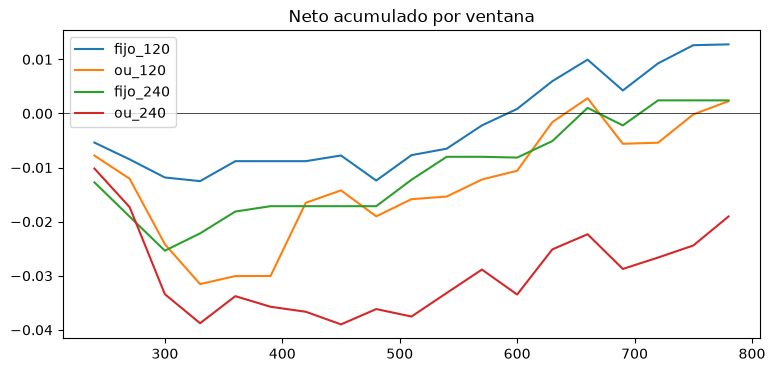

In [10]:
rows = []
for n, r in results.items():
    t = r[r.ops > 0]
    rows.append(dict(cfg=n, vida_media_h=r.hl.median(), k_med=r.k.median(), e_med=r.e.median(),
                     bruto_por_op=(t.gross/t.ops).mean(), costo_por_op=(t.cost/t.ops).mean()))
display(pd.DataFrame(rows).round(5))
fig, ax = plt.subplots(figsize=(9,4))
for n, r in results.items(): ax.plot(r.window, r.net.cumsum(), label=n)
ax.axhline(0, color='k', lw=.5); ax.set_title('Neto acumulado por ventana'); ax.legend(); plt.show()

## Fase 5 – Sensibilidad a costos (el umbral se recalcula con cada costo)

In [11]:
sens = []
for bps in [0.25, 0.5, 1.0, 2.0]:
    for name, (td, mode) in {'ou_120':(120,'ou'), 'ou_240':(240,'ou')}.items():
        r = run_cfg(data, td, mode, cost_bps=bps)
        sens.append(dict(bps=bps, cfg=name, neto=r.net.mean(), p_neto=stats.ttest_1samp(r.net,0).pvalue,
                         abstenidas=int((r.ops==0).sum()), ops=r.ops.mean()))
display(pd.DataFrame(sens).round(5))

,bps,cfg,neto,p_neto,abstenidas,ops
0,0.25,ou_120,0.00048,0.74961,0,2.52632
1,0.25,ou_240,-0.00078,0.59198,0,1.78947
2,0.50,ou_120,0.00036,0.80979,0,2.52632
3,0.50,ou_240,-0.00086,0.55628,0,1.78947
4,1.00,ou_120,0.00012,0.93534,0,2.52632
5,1.00,ou_240,-0.00100,0.48764,0,1.78947
6,2.00,ou_120,-0.00020,0.89430,0,2.47368
7,2.00,ou_240,-0.00128,0.36672,0,1.73684


## Fase 6 – Placebo
Mismo pipeline sobre 4 caminatas aleatorias independientes (misma volatilidad y niveles iniciales). **No existe ventaja real**, así que el neto medio debe ser ≤ 0 y el bruto ≈ 0. Si el método "gana" aquí, la ventaja es del método de selección, no del mercado.

In [12]:
def placebo(n_sims=8, seed=123):
    rng = np.random.default_rng(seed); out = []
    ret = np.log(data).diff().dropna(); sd = ret.std().values
    for i in range(n_sims):
        steps = rng.standard_normal((len(data), data.shape[1])) * sd
        lv = data.iloc[0].values * np.exp(np.cumsum(steps, axis=0))
        fake = pd.DataFrame(lv, index=data.index, columns=data.columns)
        for name, (td, mode) in {'fijo_120':(120,'fixed'), 'ou_120':(120,'ou'), 'ou_240':(240,'ou')}.items():
            r = run_cfg(fake, td, mode, seed=i)
            out.append(dict(sim=i, cfg=name, bruto=r.gross.mean(), neto=r.net.mean(), abst=(r.ops==0).mean()))
    return pd.DataFrame(out)
pl = placebo()
agg = pl.groupby('cfg').agg(bruto=('bruto','mean'), neto=('neto','mean'), neto_sd=('neto','std'), abst=('abst','mean'))
agg['t_neto'] = [stats.ttest_1samp(pl[pl.cfg==c].neto, 0).statistic for c in agg.index]
display(agg.round(5))

,bruto,neto,neto_sd,abst,t_neto
cfg,,,,,
fijo_120,0.00005,-0.00019,0.00117,0.13158,-0.45511
ou_120,-0.00009,-0.00051,0.00174,0.00658,-0.82627
ou_240,0.00185,0.00151,0.00158,0.00000,2.69141


## Conclusión

**Qué se probó.** Dos cambios para reducir la rotación y los costos: (1) β anclado (calibrado una vez con 120 o 240 días y congelado en la ventana de prueba) y (2) umbrales de entrada/salida elegidos con un modelo OU que resta el costo de transacción, con abstención cuando ningún umbral compensa. Se comparó contra los umbrales fijos 2.0/0.5, con las mismas ventanas de prueba.

**Resultado.** Con contabilidad corregida (pesos congelados, costos en todas las patas), el neto normalizado quedó entre −0.0013 y +0.0005 en todas las configuraciones y costos probados (0.25 a 2 pb), con p-valores entre 0.37 y 0.93: estadísticamente indistinguible de cero. La rotación bajó a ~2.5 operaciones por ventana (vs. ~9 del estático y ~28 del dinámico), pero el neto no mejoró. Los costos ya no son el factor limitante.

**Interpretación.** El borde bruto de esta canasta es demasiado pequeño (~2% anual en la auditoría) para sostener una estrategia: reducir la rotación evita perder en costos, pero no crea ganancia. La relación entre las divisas, además, cambia con el tiempo, de modo que un β anclado envejece dentro de la ventana.

**Placebo.** Sobre caminatas aleatorias independientes, `fijo_120` y `ou_120` dieron neto ≈ 0 o ligeramente negativo (t = −0.46 y −0.83), como se espera. `ou_240` dio neto positivo (t = 2.69, solo 8 simulaciones), una señal de que la selección de umbrales por OU puede ser optimista en ruido. Un neto positivo en datos reales con ese método no sería creíble sin un placebo más grande.

**Limitaciones.** Costo uniforme de 1 pb por pata (sin spreads reales); canasta fija elegida con los mismos datos; ~19 ventanas, lo que da poca potencia estadística; el modelo OU gaussiano puede ser optimista (casi no hubo abstenciones); los p-valores no corrigen por haber probado cuatro configuraciones.

**Decisión.** No hay evidencia de un borde rentable con esta canasta a frecuencia horaria. Siguientes pasos: remuestreo a 4h/8h, costos reales por pata y, solo después, más canastas con placebo y corrección por múltiples comparaciones.